# Laminar model comparison with single-shell and BEM forward models

We'll simulate a 20 Hz burst on the white matter surface of sub-104. Can we tell which surface generated the signal? We'll compare pial and white matter models twice on the same simulated data, first with an SPM single-shell forward model and then with an MNE boundary element model (BEM). We'll use the free-energy comparison from [Tutorial 02](https://danclab.github.io/laMEG/auto_tutorials/tutorial_02_model_comparison_free_energy.html) and [Bonaiuto et al. (2018)](https://doi.org/10.1016/j.neuroimage.2017.11.068).

## Setting up the simulation

The recording gives us the sensor positions and epoch timing. Run the notebook from the laMEG `tutorials` directory with the [test data](https://osf.io/x4zd3/download) in `../test_data`.

In [1]:
import shutil
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import nibabel as nib
import numpy as np
import spm_standalone
from mne.transforms import Transform, apply_trans

from lameg.forward import ForwardOperator, prepare_mne_forward
from lameg.invert import attach_forward_operator, coregister
from lameg.laminar import model_comparison
from lameg.simulate import run_current_density_simulation
from lameg.surf import LayerSurfaceSet
from lameg.util import get_fiducial_coords, load_meg_sensor_data

subj_id = 'sub-104'
ses_id = 'ses-01'
data_dir = Path('../test_data').resolve()
session = data_dir / subj_id / 'meg' / ses_id
epoch_name = f'autoreject-{subj_id}-{ses_id}-001-btn_trial-epo'
data_file = session / 'spm' / f'spm-converted_{epoch_name}.mat'

info = mne.io.read_info(str(session / 'mne' / f'{epoch_name}.fif'))
fid_coords = get_fiducial_coords(subj_id, str(data_dir / 'participants.tsv'))

We'll copy the recording, MRI and full cortical meshes to one temporary directory. SPM writes files beside its input meshes, so we'll use these copies throughout.

In [2]:
workspace = tempfile.TemporaryDirectory()
tmp_dir = Path(workspace.name)
base_fname = tmp_dir / data_file.name
for path in (data_file, data_file.with_suffix('.dat')):
    shutil.copy2(path, tmp_dir)

# Copy the MRI, its SPM normalization, and the inner skull used by both models.
subject = data_dir / 'fs' / subj_id
mri_dir = tmp_dir / subj_id / 'mri'
mri_dir.mkdir(parents=True)
for name in ('orig.nii', 'orig.mgz', 'orig_seg8.mat', 'y_orig.nii', 'origiskull_2562.surf.gii'):
    shutil.copy2(subject / 'mri' / name, mri_dir)
skull_fname = str(mri_dir / 'origiskull_2562.surf.gii')

# The two-layer mesh contains the full pial surface followed by the full white surface.
surf_set = LayerSurfaceSet(subj_id, 2, subjects_dir=str(tmp_dir))
Path(surf_set.laminar_surf_dir).mkdir(parents=True, exist_ok=True)
for layer in (None, 'pial', 'white'):
    mesh = Path(surf_set.get_mesh_path(layer_name=layer))
    shutil.copy2(subject / 'surf' / 'laminar' / mesh.name, mesh)

## Building the BEM forward model

SPM and MNE use different MRI coordinate systems. We'll put the inner skull, cortex and MRI fiducials in FreeSurfer surface RAS, then match the MRI fiducials to their measured positions in the MEG head frame.

In [3]:
# Both MRI transforms start at the same voxel coordinates.
voxel_to_ras = nib.load(str(mri_dir / 'orig.mgz')).header.get_vox2ras_tkr()
voxel_to_native = nib.load(str(mri_dir / 'orig.nii')).affine
native_to_ras = voxel_to_ras @ np.linalg.inv(voxel_to_native)

mri_fids = [fid_coords[key] for key in ('nas', 'lpa', 'rpa')]
mri_fids = apply_trans(native_to_ras, mri_fids) / 1000  # MNE uses metres.
dig = info.get_montage().get_positions()
head_fids = [dig[key] for key in ('nasion', 'lpa', 'rpa')]
trans = Transform('mri', 'head', mne.coreg.fit_matched_points(mri_fids, head_fids))

For MEG we'll use a one-compartment BEM. The red contour shows the inner-skull boundary on the subject's MRI.

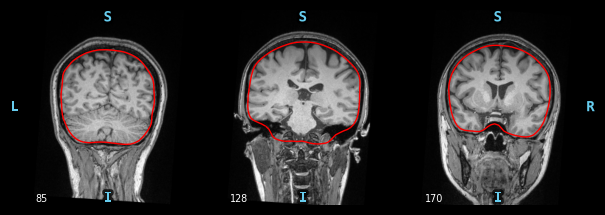

In [4]:
skull = surf_set.load_head_mesh('iskull')
bem_dir = tmp_dir / subj_id / 'bem'
bem_dir.mkdir(exist_ok=True)
mne.write_surface(str(bem_dir / 'inner_skull.surf'),
                  apply_trans(native_to_ras, skull.agg_data('pointset')), skull.agg_data('triangle'),
                  overwrite=True)

model = mne.make_bem_model(subj_id, subjects_dir=str(tmp_dir), ico=None, conductivity=(0.3,))
bem_solution = mne.make_bem_solution(model)
mne.viz.plot_bem(subject=subj_id, subjects_dir=str(tmp_dir), mri='orig.mgz',
                 slices=[85, 128, 170], show=False)
plt.show()

We'll compute the lead field at every vertex on each downsampled surface. MNE computes three dipole components per location. laMEG projects them onto the same fixed cortical directions used by the single-shell model.

In [5]:
forwards = {}
for layer in surf_set.get_layer_names():
    mesh = surf_set.load(layer, stage='ds', orientation='link_vector', fixed=True)
    points = apply_trans(native_to_ras, mesh.agg_data('pointset')) / 1000
    # MNE requires a direction for each discrete point even when computing all three components.
    directions = np.tile([0., 0., 1.], (len(points), 1))
    src = mne.setup_volume_source_space(pos={'rr': points, 'nn': directions})
    forward = mne.make_forward_solution(info, trans, src, bem_solution, meg=True, eeg=False,
                                        mindist=0., ignore_ref=False)
    forwards[layer] = str(tmp_dir / f'{layer}-fwd.fif')
    mne.write_forward_solution(forwards[layer], forward, overwrite=True)
    del forward

## Preparing the surfaces for model comparison

The sub-104 epochs all have the same condition. We'll average them to get a single-trial template for the simulation, then coregister the cortex and sensors using the three fiducials.

In [6]:
spm = spm_standalone.initialize()
spm.spm_standalone('function', 'spm_eeg_average', {'D': str(base_fname)}, nargout=0)
template = str(tmp_dir / ('m' + base_fname.name))

coregister(fid_coords, template, surf_set, iskull_fname=skull_fname, viz=False, spm_instance=spm)

A vertex outside the skull at either depth drops out of both models. laMEG matches the shared locations and keeps their original cortical vertex numbers.

In [7]:
prepared = prepare_mne_forward(forwards, surf_set, tmp_dir, reference=template, info=info,
                               ignore_ref=False, allow_nominal_ctf_coils=True)
bem = prepared.operator
print(f'{bem.n_columns:,} of {surf_set.get_vertices_per_layer():,} vertices retained per surface')

46,504 of 51,091 vertices retained per surface


## Building the single-shell forward model

We'll give SPM the same inner skull and the same retained pial and white vertices. SPM uses the measured CTF pickup geometry. MNE uses the nominal CTF coils for this acquisition.

In [8]:
coregister(fid_coords, template, prepared.surfaces, forward_model_type='Single Shell',
           iskull_fname=skull_fname, viz=False, spm_instance=spm)

# Ask SPM to compute the lead field on the registered mesh, then read it in sensor units.
spm.spm_standalone('eval', f"D = spm_eeg_load('{template}'); spm_eeg_lgainmat(D);", nargout=0)
mesh_fname = prepared.surfaces.get_mesh_path()
single_shell = ForwardOperator.from_spm(template, mesh_fname, surf_set.get_layer_names(),
                                        allow_undefined_gain=True)

## Plotting the forward models

We'll simulate a white matter source in the right inferior temporal cortex. Each map shows the field that a 1 nA m dipole at this vertex produces at the sensors. We'll use the same color scale for both maps.

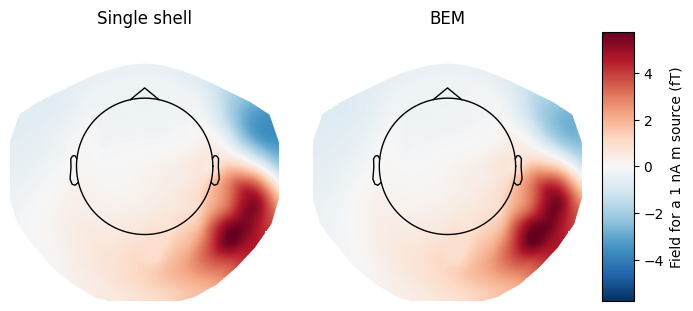

In [9]:
sim_vertex = 46846  # Right inferior temporal cortex, on the original downsampled surface
column = prepared.support.map_indices([sim_vertex])[0]
models = [('Single shell', single_shell), ('BEM', bem)]
fields = [forward.layer('white').gain[:, column] for _, forward in models]

# Arrange the sensor locations in the same order as the gain rows.
sensors = mne.pick_channels(info.ch_names, list(bem.channel_names), ordered=True)
sensor_info = mne.pick_info(info, sensors)
limit = np.max(np.abs(fields))
fig, axes = plt.subplots(1, 2, figsize=(7, 3), constrained_layout=True)
for ax, (name, _), field in zip(axes, models, fields):
    im, _ = mne.viz.plot_topomap(field, sensor_info, ch_type='mag', axes=ax, show=False,
                                 cmap='RdBu_r', vlim=(-limit, limit), contours=0, sensors=False)
    ax.set_title(name)
fig.colorbar(im, ax=axes, label='Field for a 1 nA m source (fT)')
plt.show()

## Simulating a white matter source

We'll simulate two cycles of a 20 Hz oscillation between 100 and 200 ms. Tapering the ends brings the source current smoothly back to zero.

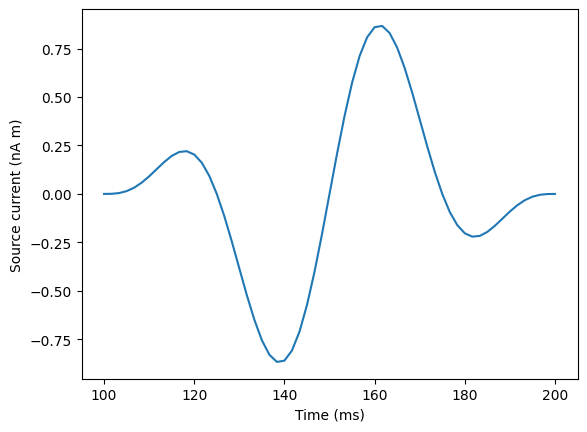

In [10]:
_, time_ms, _ = load_meg_sensor_data(template)
time_ms = np.round(time_ms, 8)
burst = (time_ms >= 100) & (time_ms <= 200)
t = (time_ms[burst] - 100) / 1000
sim_signal = np.zeros_like(time_ms)
sim_signal[burst] = np.sin(2 * np.pi * 20 * t) * np.hanning(t.size)

plt.plot(time_ms[burst], sim_signal[burst])
plt.xlabel('Time (ms)')
plt.ylabel('Source current (nA m)')
plt.show()

We'll use the BEM to project this source to the sensors. SPM scales the noise to the mean, across sensors, of the signal's standard deviation over the whole epoch. At the 0 dB setting below, the signal-to-noise RMS ratio during the burst is about +14.9 dB. A fixed noise seed lets us repeat the example.

In [11]:
# Select the BEM gain in the SPM recording used by the simulator.
attach_forward_operator(template, bem, 0, spm, mesh_fname)
white_vertex = prepared.surfaces.get_multilayer_vertex('white', int(column))
dipole_moment = 1.    # nA m
sim_patch_size = 0.1  # mm, smaller than the spacing at this vertex
SNR = 0              # dB, using SPM's simulation convention
spm.spm_standalone('eval', 'rng(16);', nargout=0)

sim_fname = run_current_density_simulation(
    template, 'sim_', white_vertex, sim_signal[None, :], dipole_moment, sim_patch_size, SNR,
    viz=False, spm_instance=spm)

## Model comparison (pial − white matter)

We'll fit a pial model and a white matter model to the same simulated recording with each forward. The empirical Bayesian beamformer (EBB) estimates source activity across the whole retained surface, without a prior on the simulation vertex. We use the time window containing the burst. The first inversion builds the smoothing matrices for both full surfaces. This can take several hours on one CPU. SPM reuses them for the second comparison.

In [12]:
settings = dict(patch_size=0.1, n_temp_modes=4, n_spatial_modes='all', woi=[100., 200.])
delta_F = []
for name, forward in models:
    F, _ = model_comparison(fid_coords, sim_fname, prepared.surfaces, method='EBB',
                            forward_operator=forward, forward_kwargs={'iskull_fname': skull_fname},
                            invert_kwargs=settings, spm_instance=spm, viz=False)
    # As in Tutorial 02, the first model is pial and the second is white.
    pial_F, white_F = np.ravel(F)
    delta_F.append(pial_F - white_F)
    print(f'{name}: {pial_F - white_F:+.2f}')

Single shell: +14.73
BEM: -56.18


Positive values favor the pial model. Negative values favor the white matter model, which is where we simulated the source.

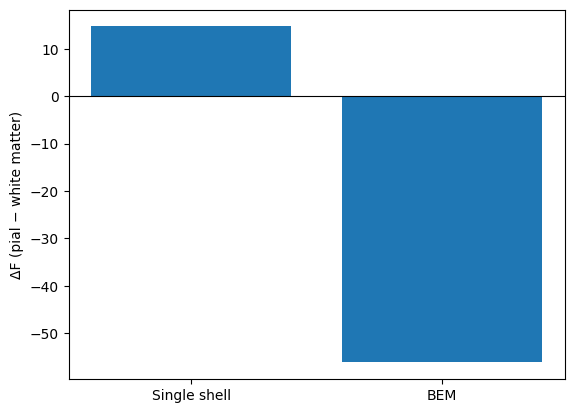

In [13]:
plt.bar(['Single shell', 'BEM'], delta_F)
plt.axhline(0, linewidth=0.8, color='black')
plt.ylabel('ΔF (pial − white matter)')
plt.show()

At this vertex, single shell favors pial (ΔF ≈ +14.7) and BEM favors the simulated white matter surface (ΔF ≈ −56.2). We chose the vertex to illustrate a disagreement, and the BEM also generated the data.

We'll close SPM and remove the temporary files when we're finished.

In [14]:
spm.terminate()
workspace.cleanup()